# Sales Car Analyst

##### 1. Cabang mana yang penjualannya (pendapatan) paling tinggi?

##### 2. Kategori mobil apa yang paling laku (dari jumlah unit terjual)?

##### 3. Berapa persen transaksi yang berhasil (completed) VS cancelled VS refund?

##### 4. Metode pembayaran apa yang paling sering dipakai?

##### 5. Bagaimana trend jumlah transaksi per bulan

##### 6. 5 mobil apa saja yang memiliki harga tertinggi dan dari cabang mana dan kategori apa

##### 7. Berapa rata-rata diskon per cabang?

##### 8. Buatkan grafik perbandingan harga rata-rata per kategori mobil

##### 9. Cabang dan kategori mobil apa yang menghasilkan pendapatan paling besar?

##### 10. Berapa rata-rata harga per unit (price) untuk masing masing kombinasi cabang dan kategori

## Import Sales Data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [2]:
df = pd.read_csv('showroom_mobil.csv', header=0)

## Viewing Data Information

In [3]:
df.head(10)

,sales_date,order_id,customer_name,branch,product_name,category,color,price,quantity,payment_type,trade_in,discount,total,total_sales,status,branch_address
0,2025-12-13,TRX00001,Customer_913,Jakarta,Daihatsu Xenia 1.5 R CVT,MPV,Silver Metalik,240000000,1,Cash + Trade In,74000000,0,240000000,166000000,completed,"Jl. MT. Haryono No. 12, Jakarta"
1,2025-10-15,TRX00002,Customer_261,Jakarta,Toyota Rush 1.5 S GR Sport CVT,SUV,Hitam Metalik,300000000,1,Kredit,0,0,300000000,300000000,completed,"Jl. MT. Haryono No. 12, Jakarta"
2,2025-01-04,TRX00003,Customer_4465,Kendari,Honda BR-V 1.5 E CVT,MPV,Merah,310000000,1,Kredit + Trade In,111000000,0,310000000,199000000,completed,"Jl. Ahmad Yani No. 33, Kendari"
3,2025-02-17,TRX00004,Customer_2788,Padang,Honda Brio Satya E CVT,Hatchback,Merah,190000000,1,Kredit,0,0,190000000,190000000,completed,"Jl. Khatib Sulaiman No. 10, Padang"
4,2025-10-02,TRX00005,Customer_2941,Karawang,Isuzu D-Max Double Cabin 4x4 AT,Pickup,Hitam Metalik,520000000,1,Cash + Trade In,93000000,0,520000000,427000000,refund,"Jl. Ahmad Yani No. 5, Karawang"
5,2025-07-05,TRX00006,Customer_3101,Bandung,Wuling Air ev Long Range,City Car (EV),Abu-abu,250000000,1,Kredit,0,0,250000000,250000000,completed,"Jl. Soekarno Hatta No. 88, Bandung"
6,2025-02-21,TRX00007,Customer_570,Jakarta,Honda BR-V 1.5 E CVT,MPV,Hitam Metalik,310000000,2,Kredit + Trade In,224000000,0,620000000,396000000,completed,"Jl. MT. Haryono No. 12, Jakarta"
7,2025-12-16,TRX00008,Customer_2989,Pontianak,Mitsubishi Pajero Sport Dakar 4x2 AT,SUV,Putih Pearl,580000000,1,Kredit,0,0,580000000,580000000,completed,"Jl. Ahmad Yani No. 45, Pontianak"
8,2025-11-24,TRX00009,Customer_1402,Semarang,Honda BR-V 1.5 E CVT,MPV,Silver Metalik,310000000,1,Kredit,0,0,310000000,310000000,completed,"Jl. Setiabudi No. 60, Semarang"
9,2025-07-25,TRX00010,Customer_1800,Karawang,Toyota Innova Zenix 2.0 V CVT,MPV,Hitam Metalik,450000000,1,Kredit + Trade In,167000000,0,450000000,283000000,completed,"Jl. Ahmad Yani No. 5, Karawang"


In [4]:
df.tail(10)

,sales_date,order_id,customer_name,branch,product_name,category,color,price,quantity,payment_type,trade_in,discount,total,total_sales,status,branch_address
9990,2025-08-01,TRX09991,Customer_1693,Jakarta,Toyota Fortuner 2.4 VRZ 4x2 AT,SUV,Coklat Metalik,580000000,1,Cash,0,0,580000000,580000000,completed,"Jl. MT. Haryono No. 12, Jakarta"
9991,2025-10-20,TRX09992,Customer_4050,Karawang,Isuzu D-Max Double Cabin 4x4 AT,Pickup,Abu-abu Granite,520000000,1,Cash,0,0,520000000,520000000,cancelled,"Jl. Ahmad Yani No. 5, Karawang"
9992,2025-08-23,TRX09993,Customer_2507,Kendari,Wuling Almaz RS Pro AT,SUV,Hitam Metalik,320000000,1,Kredit + Trade In,240000000,0,320000000,80000000,refund,"Jl. Ahmad Yani No. 33, Kendari"
9993,2025-10-22,TRX09994,Customer_3040,Jakarta,Mitsubishi Xpander Ultimate CVT,MPV,Abu-abu Titanium,320000000,1,Cash + Trade In,271000000,0,320000000,49000000,completed,"Jl. MT. Haryono No. 12, Jakarta"
9994,2025-11-30,TRX09995,Customer_1613,Batam,Honda HR-V 1.5 E CVT,SUV,Putih Mutiara,380000000,1,Cash + Trade In,84000000,0,380000000,296000000,completed,"Jl. Engku Putri No. 9, Batam"
9995,2025-03-30,TRX09996,Customer_335,Karawang,Daihatsu Xenia 1.5 R CVT,MPV,Hitam Metalik,240000000,1,Kredit,0,0,240000000,240000000,completed,"Jl. Ahmad Yani No. 5, Karawang"
9996,2025-10-07,TRX09997,Customer_665,Semarang,Nissan Livina VE AT,MPV,Putih Mutiara,260000000,1,Cash,0,0,260000000,260000000,cancelled,"Jl. Setiabudi No. 60, Semarang"
9997,2025-06-12,TRX09998,Customer_414,Malang,Suzuki Ertiga GX AT,MPV,Silver Metalik,260000000,1,Cash,0,0,260000000,260000000,completed,"Jl. Soekarno Hatta No. 77, Malang"
9998,2025-12-28,TRX09999,Customer_1113,Kendari,Toyota Avanza 1.5 G CVT,MPV,Silver Metalik,260000000,1,Kredit,0,0,260000000,260000000,completed,"Jl. Ahmad Yani No. 33, Kendari"
9999,2025-08-19,TRX10000,Customer_3962,Palembang,Wuling Almaz RS Pro AT,SUV,Hitam Metalik,320000000,1,Cash,0,0,320000000,320000000,completed,"Jl. Kolonel H. Barlian No. 21, Palembang"


In [5]:
df.shape

(10000, 16)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   sales_date      10000 non-null  object
 1   order_id        10000 non-null  object
 2   customer_name   10000 non-null  object
 3   branch          10000 non-null  object
 4   product_name    10000 non-null  object
 5   category        10000 non-null  object
 6   color           10000 non-null  object
 7   price           10000 non-null  int64 
 8   quantity        10000 non-null  int64 
 9   payment_type    10000 non-null  object
 10  trade_in        10000 non-null  int64 
 11  discount        10000 non-null  int64 
 12  total           10000 non-null  int64 
 13  total_sales     10000 non-null  int64 
 14  status          10000 non-null  object
 15  branch_address  10000 non-null  object
dtypes: int64(6), object(10)
memory usage: 1.2+ MB


In [7]:
df.describe()

,price,quantity,trade_in,discount,total,total_sales
count,1.000000e+04,10000.000000,1.000000e+04,10000.000000,1.000000e+04,1.000000e+04
mean,3.520230e+08,1.043300,5.793070e+07,31800.000000,3.672310e+08,3.092685e+08
std,1.279790e+08,0.235862,9.138950e+07,175476.035925,1.604465e+08,1.843259e+08
min,1.900000e+08,1.000000,0.000000e+00,0.000000,1.900000e+08,-1.100000e+08
25%,2.600000e+08,1.000000,0.000000e+00,0.000000,2.600000e+08,2.180000e+08
50%,3.100000e+08,1.000000,0.000000e+00,0.000000,3.100000e+08,2.900000e+08
75%,3.800000e+08,1.000000,1.052500e+08,0.000000,4.500000e+08,3.800000e+08
max,6.500000e+08,3.000000,3.000000e+08,1000000.000000,1.950000e+09,1.950000e+09


In [8]:
df.describe(include='all')

,sales_date,order_id,customer_name,branch,product_name,category,color,price,quantity,payment_type,trade_in,discount,total,total_sales,status,branch_address
count,10000,10000,10000,10000,10000,10000,10000,1.000000e+04,10000.000000,10000,1.000000e+04,10000.000000,1.000000e+04,1.000000e+04,10000,10000
unique,365,10000,3977,10,20,5,21,NaN,NaN,4,NaN,NaN,NaN,NaN,3,10
top,2025-09-08,TRX00001,Customer_4258,Jakarta,Honda HR-V 1.5 E CVT,SUV,Hitam Metalik,NaN,NaN,Kredit,NaN,NaN,NaN,NaN,completed,"Jl. MT. Haryono No. 12, Jakarta"
freq,42,1,9,1058,557,4565,2082,NaN,NaN,4253,NaN,NaN,NaN,NaN,8966,1058
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.520230e+08,1.043300,NaN,5.793070e+07,31800.000000,3.672310e+08,3.092685e+08,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.279790e+08,0.235862,NaN,9.138950e+07,175476.035925,1.604465e+08,1.843259e+08,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.900000e+08,1.000000,NaN,0.000000e+00,0.000000,1.900000e+08,-1.100000e+08,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.600000e+08,1.000000,NaN,0.000000e+00,0.000000,2.600000e+08,2.180000e+08,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.100000e+08,1.000000,NaN,0.000000e+00,0.000000,3.100000e+08,2.900000e+08,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.800000e+08,1.000000,NaN,1.052500e+08,0.000000,4.500000e+08,3.800000e+08,NaN,NaN


In [9]:
df.columns

Index(['sales_date', 'order_id', 'customer_name', 'branch', 'product_name',
       'category', 'color', 'price', 'quantity', 'payment_type', 'trade_in',
       'discount', 'total', 'total_sales', 'status', 'branch_address'],
      dtype='object')

In [10]:
df.dtypes

,0
sales_date,object
order_id,object
customer_name,object
branch,object
product_name,object
category,object
color,object
price,int64
quantity,int64
payment_type,object


## Data Cleansing

### 1. Mengecek Missing Values

In [13]:
# Mengcopy Data Sumber
df_clean = df.copy()

In [14]:
# Mengecek dan Menghitung Missing Value
df_clean.isnull().sum()

,0
sales_date,0
order_id,0
customer_name,0
branch,0
product_name,0
category,0
color,0
price,0
quantity,0
payment_type,0


### 2. Mengecek Duplikasi Data

In [15]:
# Mengecek dan Menghitung duplikasi data
df_clean.duplicated().sum()

np.int64(0)

In [16]:
# Mengecek dan Menampilkan data duplikat berdasarkan kolom order_id
df_clean[df_clean.duplicated(subset= ['order_id'], keep= False)]

,sales_date,order_id,customer_name,branch,product_name,category,color,price,quantity,payment_type,trade_in,discount,total,total_sales,status,branch_address


### 3. Mengecek dan Mengubah Tipe Data sales_date

In [18]:
# Mengubah tipe data pada kolom sales_date
df_clean['sales_date'] = pd.to_datetime(df_clean['sales_date'])

In [17]:
# Mengecek data tanggal apakah ada yang gagal dikonversi (jadi kosong)
df['sales_date'].isnull().sum()

np.int64(0)

In [19]:
# Mengecek ulang tipe data pada setiap kolom
df_clean.dtypes

,0
sales_date,datetime64[ns]
order_id,object
customer_name,object
branch,object
product_name,object
category,object
color,object
price,int64
quantity,int64
payment_type,object


### 4. Mengecek Nilai Unik

In [20]:
# Mengecek nilai unik di kolom order_id
df_clean['order_id'].unique()

array(['TRX00001', 'TRX00002', 'TRX00003', ..., 'TRX09998', 'TRX09999',
       'TRX10000'], shape=(10000,), dtype=object)

In [21]:
# Mengecek nilai unik di kolom branch
sorted(df_clean['branch'].unique())

['Bandung',
 'Batam',
 'Jakarta',
 'Karawang',
 'Kendari',
 'Malang',
 'Padang',
 'Palembang',
 'Pontianak',
 'Semarang']

In [22]:
# Mengecek nilai unik di kolom payment_type
sorted(df_clean['payment_type'].unique())

['Cash', 'Cash + Trade In', 'Kredit', 'Kredit + Trade In']

In [23]:
# Menghilangkan spasi di awal dan akhir kata di kolom branch
df_clean['branch'] = df_clean['branch'].str.strip()
# Menjadikan awal kata menjadi kapital
df_clean['branch'] = df_clean['branch'].str.title()

print("Menghilangkan spasi awal dan akhir kata")
print(sorted(df_clean['branch'].unique()))

print("\nMenjadikan awal kata menjadi kapital")
print("", sorted(df_clean['branch'].unique()))

Menghilangkan spasi awal dan akhir kata
['Bandung', 'Batam', 'Jakarta', 'Karawang', 'Kendari', 'Malang', 'Padang', 'Palembang', 'Pontianak', 'Semarang']

Menjadikan awal kata menjadi kapital
 ['Bandung', 'Batam', 'Jakarta', 'Karawang', 'Kendari', 'Malang', 'Padang', 'Palembang', 'Pontianak', 'Semarang']


In [24]:
# Menghilangkan spasi di awal dan akhir kata di kolom category
df_clean['category'] = df_clean['category'].str.strip()

# Menjadikan awal kalimat menjadi kapital
df_clean['category'] = df_clean['category'].str.upper()

print('Menghilangkan spasi awal dan akhir kata')
print(sorted(df_clean['category'].unique()))

print('\nMenjadikan awal kalimat menjadi kapital')
print(sorted)

Menghilangkan spasi awal dan akhir kata
['CITY CAR (EV)', 'HATCHBACK', 'MPV', 'PICKUP', 'SUV']

Menjadikan awal kalimat menjadi kapital
<built-in function sorted>


## Data Transformation

### 1. Pecah Kolom Tanggal jadi Bulan dan Tahun

In [25]:
df_clean["sales_month"] = df_clean["sales_date"].dt.month
df_clean["sales_year"] = df_clean["sales_date"].dt.year
df_clean["sales_month_name"] = df_clean["sales_date"].dt.month_name()

df_clean[["sales_date", "sales_year", "sales_month", "sales_month_name"]].head()

,sales_date,sales_year,sales_month,sales_month_name
0,2025-12-13,2025,12,December
1,2025-10-15,2025,10,October
2,2025-01-04,2025,1,January
3,2025-02-17,2025,2,February
4,2025-10-02,2025,10,October


### 2. Rename Nama Kolom

In [26]:
df_rename = df_clean.rename(columns={"total" : "total_sales_before_trade_in"})

df_rename.columns.tolist()

['sales_date',
 'order_id',
 'customer_name',
 'branch',
 'product_name',
 'category',
 'color',
 'price',
 'quantity',
 'payment_type',
 'trade_in',
 'discount',
 'total_sales_before_trade_in',
 'total_sales',
 'status',
 'branch_address',
 'sales_month',
 'sales_year',
 'sales_month_name']

### 3. Binning Kategori Harga

In [27]:
def kategori_harga(harga):
  if harga < 250000000:
    return "Murah"
  elif harga <= 400000000:
    return "Menegah"
  else:
    return "Mahal"

df_clean["segmen_harga"] = df_clean["price"].apply(kategori_harga)
df_clean[["product_name", "price", "segmen_harga"]].head()

,product_name,price,segmen_harga
0,Daihatsu Xenia 1.5 R CVT,240000000,Murah
1,Toyota Rush 1.5 S GR Sport CVT,300000000,Menegah
2,Honda BR-V 1.5 E CVT,310000000,Menegah
3,Honda Brio Satya E CVT,190000000,Murah
4,Isuzu D-Max Double Cabin 4x4 AT,520000000,Mahal


## Data Sorting, Filtering, dan Grouping

### 1. Filtering

In [28]:
# Filter transaksi dengan status completed
transaksi_completed = df_clean[df_clean["status"] == "completed"]
print("Jumlah transaksi completed: ", len(transaksi_completed))
transaksi_completed.head()

Jumlah transaksi completed:  8966


,sales_date,order_id,customer_name,branch,product_name,category,color,price,quantity,payment_type,trade_in,discount,total,total_sales,status,branch_address,sales_month,sales_year,sales_month_name,segmen_harga
0,2025-12-13,TRX00001,Customer_913,Jakarta,Daihatsu Xenia 1.5 R CVT,MPV,Silver Metalik,240000000,1,Cash + Trade In,74000000,0,240000000,166000000,completed,"Jl. MT. Haryono No. 12, Jakarta",12,2025,December,Murah
1,2025-10-15,TRX00002,Customer_261,Jakarta,Toyota Rush 1.5 S GR Sport CVT,SUV,Hitam Metalik,300000000,1,Kredit,0,0,300000000,300000000,completed,"Jl. MT. Haryono No. 12, Jakarta",10,2025,October,Menegah
2,2025-01-04,TRX00003,Customer_4465,Kendari,Honda BR-V 1.5 E CVT,MPV,Merah,310000000,1,Kredit + Trade In,111000000,0,310000000,199000000,completed,"Jl. Ahmad Yani No. 33, Kendari",1,2025,January,Menegah
3,2025-02-17,TRX00004,Customer_2788,Padang,Honda Brio Satya E CVT,HATCHBACK,Merah,190000000,1,Kredit,0,0,190000000,190000000,completed,"Jl. Khatib Sulaiman No. 10, Padang",2,2025,February,Murah
5,2025-07-05,TRX00006,Customer_3101,Bandung,Wuling Air ev Long Range,CITY CAR (EV),Abu-abu,250000000,1,Kredit,0,0,250000000,250000000,completed,"Jl. Soekarno Hatta No. 88, Bandung",7,2025,July,Menegah


In [29]:
# Filter transaksi dari branch Jakarta dengan kategori SUV
transaksi_suv_jakarta = df_clean[(df_clean["branch"] == "Jakarta") & (df_clean["category"] == "SUV")]
transaksi_suv_jakarta.head()

,sales_date,order_id,customer_name,branch,product_name,category,color,price,quantity,payment_type,trade_in,discount,total,total_sales,status,branch_address,sales_month,sales_year,sales_month_name,segmen_harga
1,2025-10-15,TRX00002,Customer_261,Jakarta,Toyota Rush 1.5 S GR Sport CVT,SUV,Hitam Metalik,300000000,1,Kredit,0,0,300000000,300000000,completed,"Jl. MT. Haryono No. 12, Jakarta",10,2025,October,Menegah
27,2025-04-20,TRX00028,Customer_4429,Jakarta,Toyota Rush 1.5 S GR Sport CVT,SUV,Hitam Metalik,300000000,1,Kredit,0,0,300000000,300000000,completed,"Jl. MT. Haryono No. 12, Jakarta",4,2025,April,Menegah
41,2025-01-22,TRX00042,Customer_4470,Jakarta,Mitsubishi Pajero Sport Dakar 4x2 AT,SUV,Abu-abu Quartz,580000000,1,Kredit,0,0,580000000,580000000,completed,"Jl. MT. Haryono No. 12, Jakarta",1,2025,January,Mahal
147,2025-04-19,TRX00148,Customer_3465,Jakarta,Daihatsu Terios 1.5 R CVT,SUV,Merah,290000000,1,Kredit,0,0,290000000,290000000,completed,"Jl. MT. Haryono No. 12, Jakarta",4,2025,April,Menegah
182,2025-07-17,TRX00183,Customer_2864,Jakarta,Suzuki XL7 Beta AT,SUV,Putih Mutiara,260000000,1,Kredit,0,0,260000000,260000000,refund,"Jl. MT. Haryono No. 12, Jakarta",7,2025,July,Menegah


In [30]:
# Filter transaksi completed pada category SUV
transaksi_completed_suv = df_clean[(df_clean['status'] == 'completed') & (df_clean['category'] == 'SUV')]
transaksi_completed_suv.head()

,sales_date,order_id,customer_name,branch,product_name,category,color,price,quantity,payment_type,trade_in,discount,total,total_sales,status,branch_address,sales_month,sales_year,sales_month_name,segmen_harga
1,2025-10-15,TRX00002,Customer_261,Jakarta,Toyota Rush 1.5 S GR Sport CVT,SUV,Hitam Metalik,300000000,1,Kredit,0,0,300000000,300000000,completed,"Jl. MT. Haryono No. 12, Jakarta",10,2025,October,Menegah
7,2025-12-16,TRX00008,Customer_2989,Pontianak,Mitsubishi Pajero Sport Dakar 4x2 AT,SUV,Putih Pearl,580000000,1,Kredit,0,0,580000000,580000000,completed,"Jl. Ahmad Yani No. 45, Pontianak",12,2025,December,Mahal
12,2025-02-26,TRX00013,Customer_1797,Pontianak,Wuling Almaz RS Pro AT,SUV,Hitam Metalik,320000000,1,Cash,0,0,320000000,320000000,completed,"Jl. Ahmad Yani No. 45, Pontianak",2,2025,February,Menegah
24,2025-12-11,TRX00025,Customer_3532,Karawang,Suzuki XL7 Beta AT,SUV,Silver Metalik,260000000,1,Cash + Trade In,80000000,0,260000000,180000000,completed,"Jl. Ahmad Yani No. 5, Karawang",12,2025,December,Menegah
26,2025-02-20,TRX00027,Customer_3790,Palembang,Toyota Rush 1.5 S GR Sport CVT,SUV,Silver Metalik,300000000,1,Kredit + Trade In,55000000,0,300000000,245000000,completed,"Jl. Kolonel H. Barlian No. 21, Palembang",2,2025,February,Menegah


### 2. Sorting

In [31]:
# Sorting total_sales terbesar
df_clean.sort_values('total_sales', ascending=False).head()

,sales_date,order_id,customer_name,branch,product_name,category,color,price,quantity,payment_type,trade_in,discount,total,total_sales,status,branch_address,sales_month,sales_year,sales_month_name,segmen_harga
8863,2025-02-06,TRX08864,Customer_583,Karawang,Honda CR-V 1.5 Turbo RS,SUV,Hitam Metalik,650000000,3,Kredit,0,0,1950000000,1950000000,completed,"Jl. Ahmad Yani No. 5, Karawang",2,2025,February,Mahal
1984,2025-02-24,TRX01985,Customer_88,Pontianak,Honda CR-V 1.5 Turbo RS,SUV,Putih Mutiara,650000000,3,Cash,0,0,1950000000,1950000000,completed,"Jl. Ahmad Yani No. 45, Pontianak",2,2025,February,Mahal
7663,2025-04-09,TRX07664,Customer_2757,Padang,Honda CR-V 1.5 Turbo RS,SUV,Hitam Metalik,650000000,3,Kredit + Trade In,71000000,0,1950000000,1879000000,completed,"Jl. Khatib Sulaiman No. 10, Padang",4,2025,April,Mahal
9640,2025-12-02,TRX09641,Customer_4393,Palembang,Honda CR-V 1.5 Turbo RS,SUV,Putih Mutiara,650000000,3,Kredit + Trade In,154000000,0,1950000000,1796000000,completed,"Jl. Kolonel H. Barlian No. 21, Palembang",12,2025,December,Mahal
3815,2025-12-20,TRX03816,Customer_1116,Batam,Honda CR-V 1.5 Turbo RS,SUV,Hitam Metalik,650000000,3,Kredit + Trade In,198000000,0,1950000000,1752000000,refund,"Jl. Engku Putri No. 9, Batam",12,2025,December,Mahal


### 3. Grouping

In [32]:
# Grouping total_sales per cabang
total_sales_per_branch = df_clean.groupby('branch')['total_sales'].sum().sort_values(ascending=False)
total_sales_per_branch

,total_sales
branch,
Malang,324667000000
Jakarta,321206000000
Padang,320563000000
Palembang,313424000000
Bandung,309280000000
Batam,307024000000
Kendari,303587000000
Semarang,299601000000
Pontianak,297935000000


In [36]:
# Grouping rata-rata total_sales per branch
rata_rata_total_sales_per_branch = df_clean.groupby('branch')['total_sales'].mean().sort_values(ascending=False)
rata_rata_total_sales_per_branch

,total_sales
branch,
Palembang,3.194944e+08
Bandung,3.127199e+08
Batam,3.113834e+08
Kendari,3.110523e+08
Malang,3.109837e+08
Semarang,3.098252e+08
Padang,3.070527e+08
Jakarta,3.035974e+08
Karawang,3.035951e+08


In [35]:
# Grouping rata-rata harga mobil per category
rata_rata_harga_per_category = df_clean.groupby('category')['price'].mean().sort_values(ascending=False)
rata_rata_harga_per_category

,price
category,
PICKUP,5.200000e+08
SUV,4.086199e+08
MPV,2.980077e+08
CITY CAR (EV),2.500000e+08
HATCHBACK,1.900000e+08


## Exploratory Data Analysis

### 1. Cabang mana yang penjualannya (pendapatan) paling tinggi?

In [45]:
penjualan_per_branch = (
    df_clean[df_clean['status'] == 'completed']
    .groupby('branch')['total_sales']
    .sum().sort_values(ascending=False)
)

penjualan_per_branch

,total_sales
branch,
Malang,291605000000
Padang,285888000000
Jakarta,283701000000
Bandung,278617000000
Batam,278133000000
Palembang,277360000000
Kendari,275883000000
Semarang,267237000000
Pontianak,265419000000


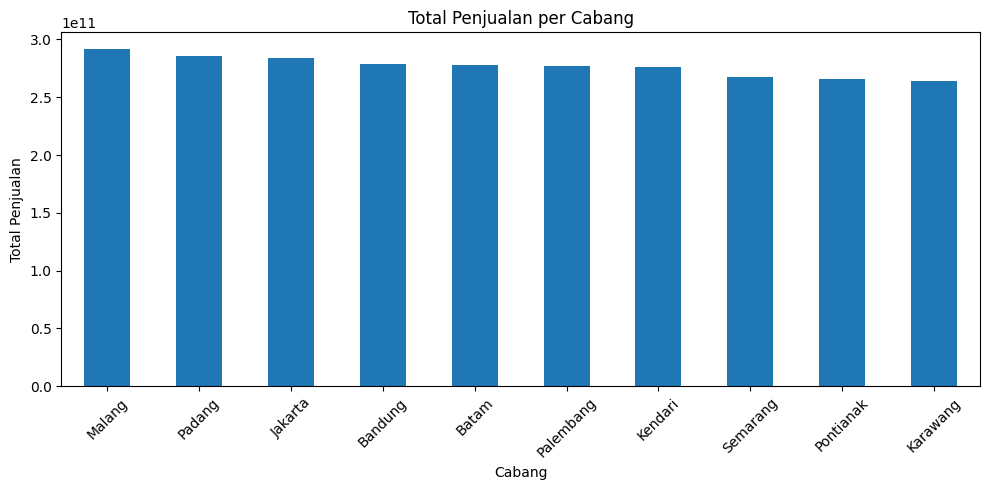

In [52]:
penjualan_per_branch.plot(kind='bar', figsize=(10,5), title='Total Penjualan per Cabang')
plt.ylabel('Total Penjualan')
plt.xlabel('Cabang')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 2. Kategori mobil apa yang paling laku (dari jumlah unit terjual)

In [54]:
unit_per_category = (
    df_clean[df_clean['status'] == 'completed']
    .groupby('category')['quantity']
    .sum().sort_values(ascending=False)
)

unit_per_category

,quantity
category,
SUV,4273
MPV,3658
HATCHBACK,489
PICKUP,466
CITY CAR (EV),456


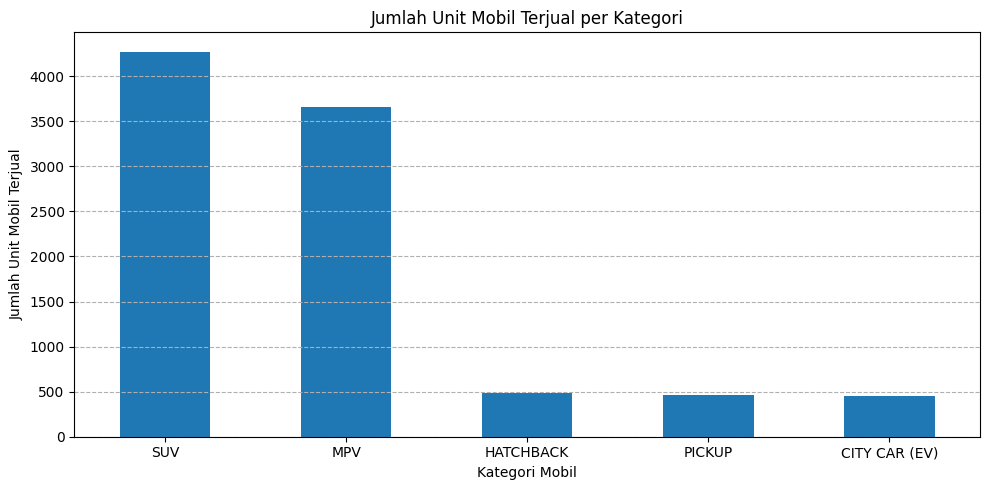

In [62]:
unit_per_category.plot(kind='bar', figsize=(10,5), title='Jumlah Unit Mobil Terjual per Kategori')
plt.ylabel('Jumlah Unit Mobil Terjual')
plt.xlabel('Kategori Mobil')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--')
plt.tight_layout()
plt.show()

### 3. Berapa persen transaksi yang berhasil (completed) VS cancelled VS refund

In [65]:
distribusi_status = df_clean['status'].value_counts(normalize=True)*100
distribusi_status.round(1)

,proportion
status,
completed,89.7
cancelled,5.4
refund,4.9


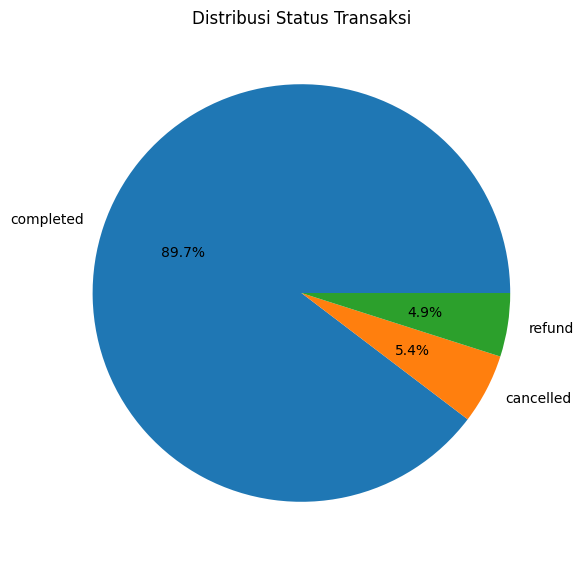

In [69]:
distribusi_status.plot(kind='pie', autopct='%1.1f%%', figsize=(6,6), title='Distribusi Status Transaksi')
plt.ylabel('')
plt.tight_layout()
plt.show()

## 4. Metode pembayaran apa yang paling sering dipakai

In [72]:
tipe_pembayaran = df_clean['payment_type'].value_counts().sort_values(ascending=False)
tipe_pembayaran

,count
payment_type,
Kredit,4253
Cash,2224
Kredit + Trade In,1999
Cash + Trade In,1524


## 5. Bagaimana tren jumlah transaksi per bulan

In [81]:
tren_bulanan = df_clean.groupby('sales_month_name')['order_id'].count()

urutan_bulan = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
tren_transaksi_bulanan = tren_bulanan.reindex(urutan_bulan)

tren_transaksi_bulanan

,order_id
sales_month_name,
January,820
February,767
March,852
April,830
May,868
June,767
July,875
August,877
September,796


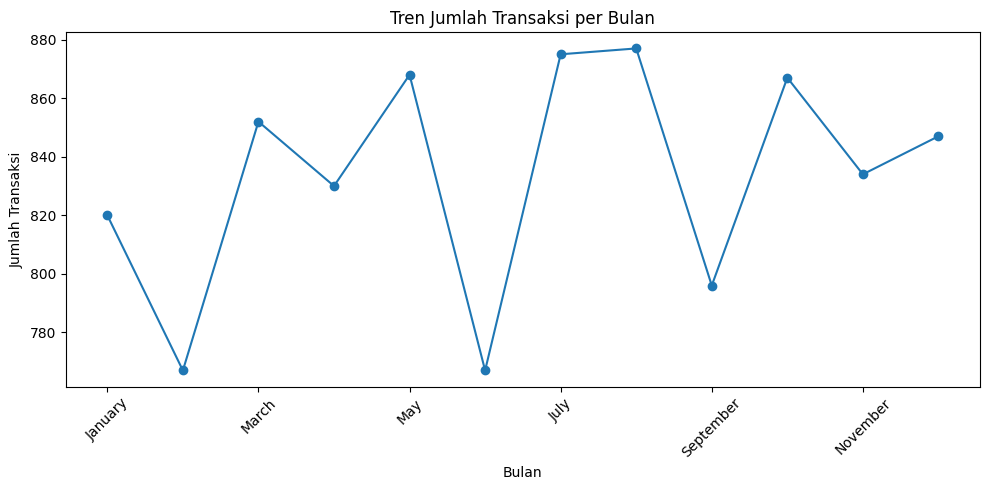

In [82]:
tren_transaksi_bulanan.plot(kind='line', marker='o', figsize=(10,5), title='Tren Jumlah Transaksi per Bulan')
plt.ylabel('Jumlah Transaksi')
plt.xlabel('Bulan')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 6. 5 mobil apa saja yang memiliki harga tertinggi beserta dari cabang mana dan kategori mobilnya apa

In [91]:
top_5_mobil_termahal = df_clean.sort_values('price', ascending=False)[['product_name', 'category', 'branch', 'price']].head()
top_5_mobil_termahal

,product_name,category,branch,price
3483,Honda CR-V 1.5 Turbo RS,SUV,Malang,650000000
3504,Honda CR-V 1.5 Turbo RS,SUV,Batam,650000000
5517,Honda CR-V 1.5 Turbo RS,SUV,Malang,650000000
5519,Honda CR-V 1.5 Turbo RS,SUV,Karawang,650000000
5462,Honda CR-V 1.5 Turbo RS,SUV,Pontianak,650000000


## 7. Berapa rata rata diskon per cabang

In [92]:
rata_rata_diskon_per_cabang = df_clean.groupby('branch')['discount'].mean().sort_values(ascending=False)
rata_rata_diskon_per_cabang

,discount
branch,
Malang,38314.176245
Semarang,35160.289555
Palembang,34658.511723
Padang,33524.904215
Jakarta,33081.285444
Pontianak,31568.228106
Batam,30425.963489
Kendari,28688.524590
Bandung,27300.303337


## 8. Bagaimana perbandingan harga rata-rata per kategori mobil dan buat grafiknya

In [93]:
rata_rata_per_category_mobil = df_clean.groupby('category')['price'].mean().sort_values(ascending=False)
rata_rata_per_category_mobil

,price
category,
PICKUP,5.200000e+08
SUV,4.086199e+08
MPV,2.980077e+08
CITY CAR (EV),2.500000e+08
HATCHBACK,1.900000e+08


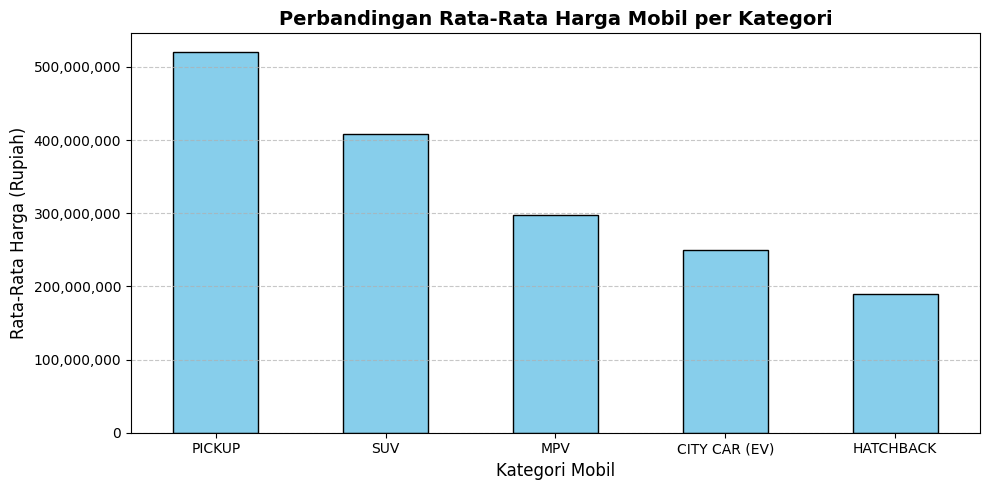

In [105]:
# Membuat visualisasi perbandingan harga rata-rata per kategori mobil
rata_rata_per_category_mobil.plot(kind='bar', figsize=(10,5), color='skyblue', edgecolor='black')

plt.title('Perbandingan Rata-Rata Harga Mobil per Kategori', fontsize=14, fontweight='bold')
plt.xlabel('Kategori Mobil', fontsize=12)
plt.ylabel('Rata-Rata Harga (Rupiah)', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Mengatur format label pada sumbu Y agar tidak menggunakan notasi ilmiah
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,.0f}".format(x)))

plt.tight_layout()
plt.show()

## 9. Cabang dan kategori mobil apa yang menghasilkan pendapatan paling besar?

In [101]:
pendapatan_cabang_kategori = (
    df_clean[df_clean['status'] == 'completed']
    .groupby(['branch', 'category'])['total_sales']
    .sum().sort_values(ascending=False)
)

pendapatan_cabang_kategori.head()

,,total_sales
branch,category,
Palembang,SUV,157626000000
Jakarta,SUV,155749000000
Malang,SUV,154891000000
Batam,SUV,151981000000
Karawang,SUV,150498000000


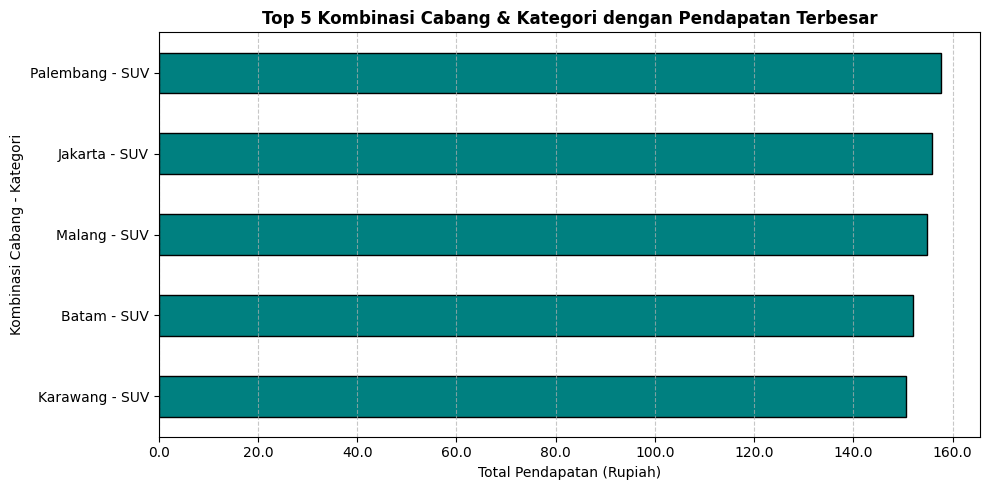

In [120]:
# Mengambil 5 kombinasi teratas dengan menjadikannya DataFrame terlebih dahulu
top_5_sales = pendapatan_cabang_kategori.reset_index().head()

# Membuat label gabungan untuk sumbu Y
top_5_sales['branch_category'] = top_5_sales['branch'] + ' - ' + top_5_sales['category']

top_5_sales['total_sales_in_billions'] = top_5_sales['total_sales'] / 1e9

# Membuat horizontal bar chart dengan parameter x dan y yang tepat
top_5_sales.plot(
    kind='barh',
    x='branch_category',
    y= 'total_sales_in_billions',
    figsize=(10, 5),
    color='teal',
    edgecolor='black',
    legend=False
)

plt.title('Top 5 Kombinasi Cabang & Kategori dengan Pendapatan Terbesar', fontsize=12, fontweight='bold')
plt.xlabel('Total Pendapatan (Rupiah)')
plt.ylabel('Kombinasi Cabang - Kategori')

# Membalikkan sumbu Y agar urutan terbesar berada di atas
plt.gca().invert_yaxis()

# Memformat sumbu X agar menampilkan angka desimal biasa (bukan notasi ilmiah)
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,.1f}".format(x)))

plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## 10. Berapa rata-rata harga per unit (price) untuk masing masing kombinasi cabang dan kategori


In [148]:
# Mengambil kombinasi cabang dan kategori dari top 5 pendapatan terbesar
top_5_keys = top_5_sales[['branch', 'category']]

# Melakukan merge dengan df_clean untuk mendapatkan data transaksi yang sesuai
data_top_5 = df_clean.merge(top_5_keys, on=['branch', 'category'])

# Menghitung rata-rata harga per unit (price) untuk kombinasi tersebut
rata_rata_harga_top_5 = data_top_5.groupby(['branch', 'category'])['price'].mean().reset_index()

# Mengurutkan berdasarkan harga rata-rata tertinggi
rata_rata_harga_top_5 = rata_rata_harga_top_5.sort_values(by='price', ascending=False)

rata_rata_harga_top_5.head()

,branch,category,price
0,Batam,SUV,"414,049,217.00"
3,Malang,SUV,"413,973,799.13"
4,Palembang,SUV,"412,963,752.67"
1,Jakarta,SUV,"407,800,829.88"
2,Karawang,SUV,"398,325,991.19"
